In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import sys
from ast import literal_eval
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import regionmask
import seaborn as sns
import windpowerlib.power_curves as pc
import xarray as xr
from windpowerlib import wind_turbine as wt
from windpowerlib.data import store_turbine_data_from_oedb

sns.set_style("whitegrid", {"grid.color": ".93"})

sys.path.append("../..")

from src.conversion_energy.wind import (
    compute_power_law_exponent,
    compute_smooth_power_curve,
    compute_wind_power,
    extrapolate_wind_speed,
)
from src.data_processing.load_data import ClimateModelData
from src.utils.utils_xarray import sel_extent

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/bias_correction_2024/share/proj failed


In [3]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"

path_energy_ch = path_data_processed / "energy" / "ch"

path_figs = Path(paths["path_figs"])

In [4]:
europe_turbines = ["E-126/7580", "SWT120/3600", "SWT142/3150"]
ch_turbines = ["E-82/2300", "E-92/2350", "V90/2000", "V112/3300"]
ch_hub_heights = {"E-82/2300": 98, "E-92/2350": 98, "V90/2000": 95, "V112/3300": 94}
df_turbine = store_turbine_data_from_oedb()

In [5]:
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}
extent_ch = {"lat_min": 45.8, "lat_max": 47.9, "lon_min": 5.9, "lon_max": 10.5}

In [6]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

# Smoothed Power Curves

In [ ]:
power_curves_europe_smoothed = {
    turbine: compute_smooth_power_curve(turbine) for turbine in europe_turbines
}
power_curves_ch_smoothed = {
    turbine: compute_smooth_power_curve(turbine) for turbine in ch_turbines
}

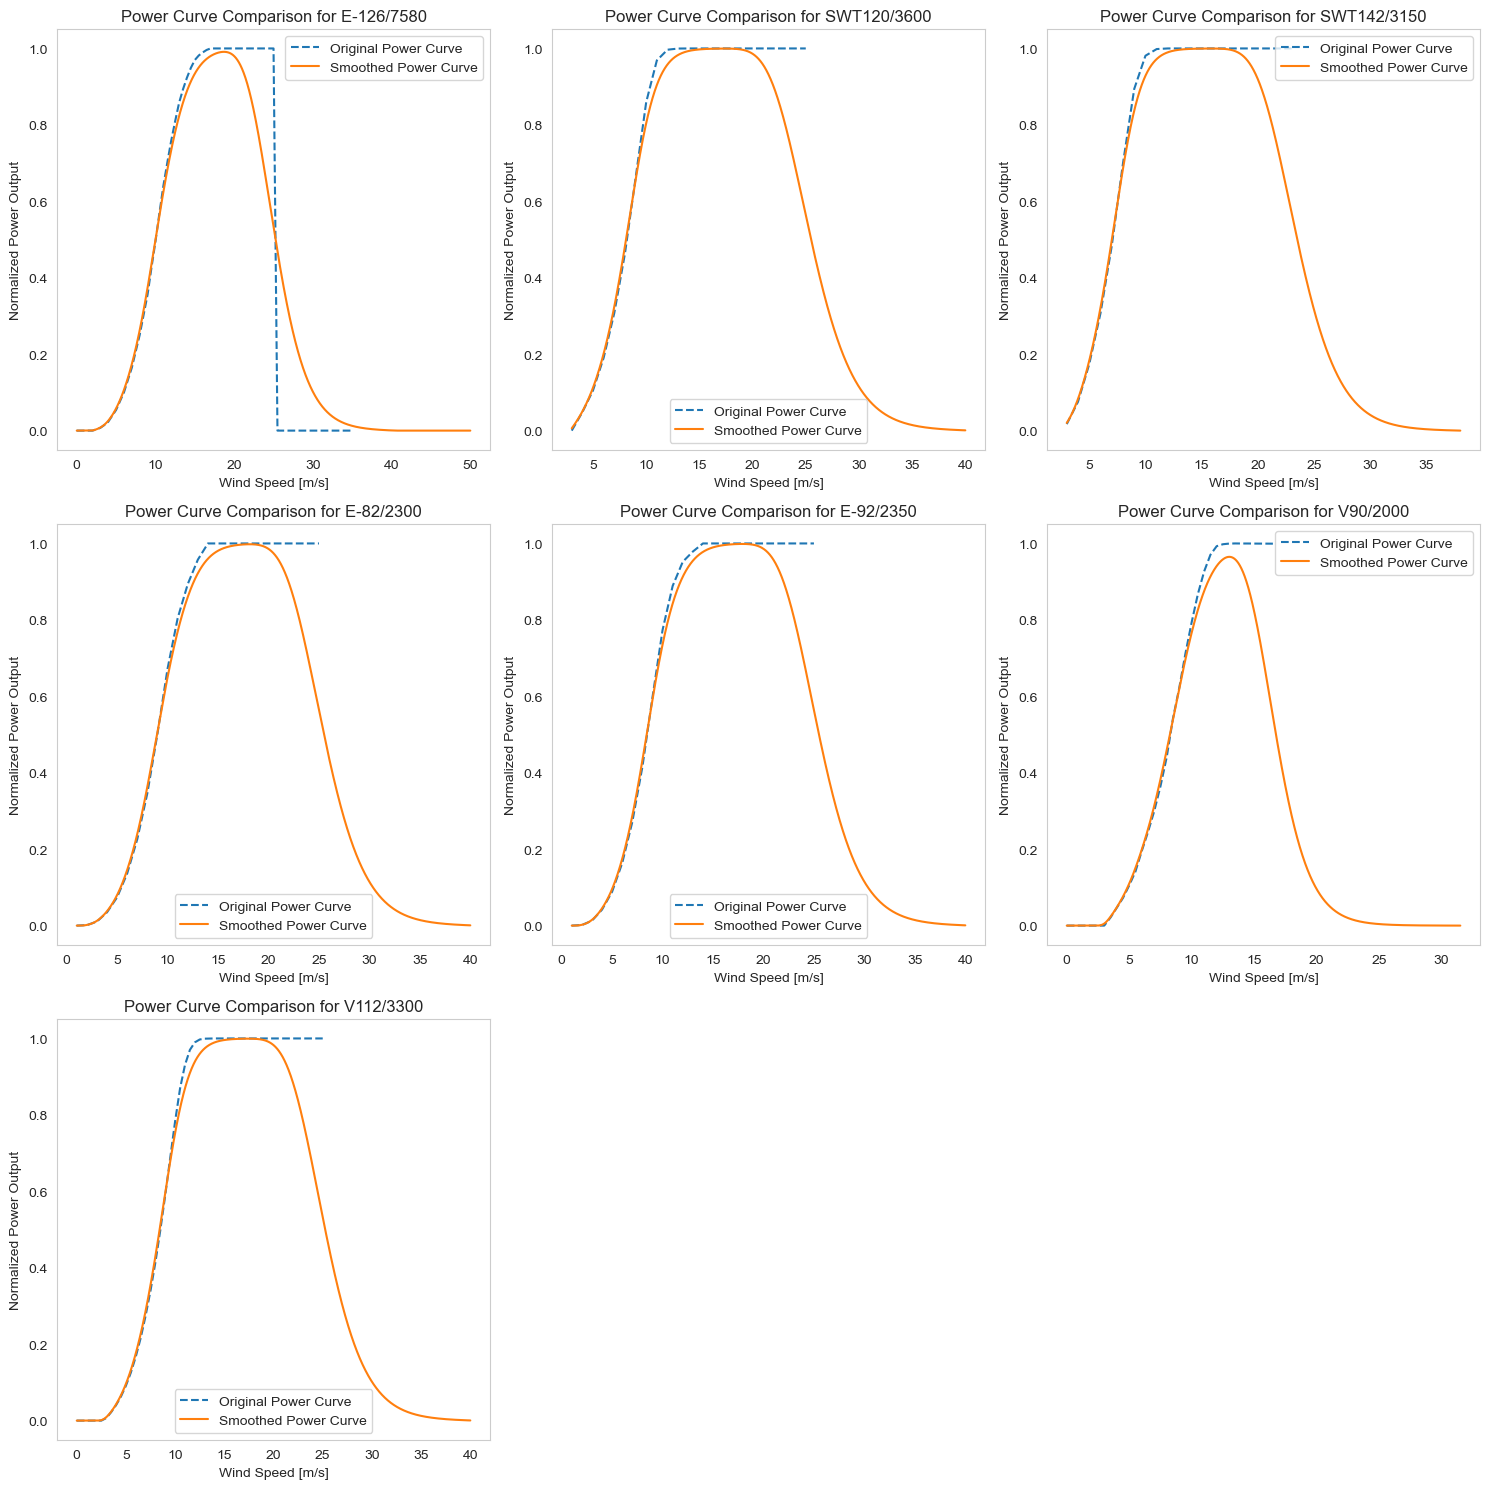

In [ ]:
# Combine all turbines into a single list
all_turbines = europe_turbines + ch_turbines

# Define the number of rows and columns for the grid
n_cols = 3
n_rows = (len(all_turbines) + n_cols - 1) // n_cols  # Calculate rows needed

# Create subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
axes = axes.flatten()  # Flatten the axes array for easier indexing

# Loop through each turbine and plot the power curves
for i, turbine_type in enumerate(all_turbines):
    try:
        # Compute smoothed power curve
        power_curve_smoothed = compute_smooth_power_curve(turbine_type)

        # Extract original power curve
        original_power_curve = df_turbine.loc[
            df_turbine["turbine_type"] == turbine_type
        ].iloc[0]
        original_power_curve["power_curve_wind_speeds"] = np.array(
            literal_eval(original_power_curve["power_curve_wind_speeds"])
        )
        original_power_curve["power_curve_values"] = np.array(
            literal_eval(original_power_curve["power_curve_values"])
        )

        # Normalize original power curve
        original_power_curve["power_curve_values"] /= original_power_curve[
            "power_curve_values"
        ].max()

        # Plot original and smoothed power curves
        ax = axes[i]
        ax.plot(
            original_power_curve["power_curve_wind_speeds"],
            original_power_curve["power_curve_values"],
            label="Original Power Curve",
            linestyle="--",
        )
        ax.plot(
            power_curve_smoothed.index,
            power_curve_smoothed[turbine_type.replace("/", "_")],
            label="Smoothed Power Curve",
        )
        ax.set_xlabel("Wind Speed [m/s]")
        ax.set_ylabel("Normalized Power Output")
        ax.set_title(f"Power Curve Comparison for {turbine_type}")
        ax.legend()
        ax.grid()
    except Exception as e:
        print(f"Error processing turbine {turbine_type}: {e}")

# Hide unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Adjust layout
plt.tight_layout()
plt.show()

One turbine (**V90/2000**) has a profile where the normalised values never attain 1.

Max in original: 1.0, for wind speed: 13.5
Max in smoothened version: 0.9649663159466331, for wind speed: 13.0


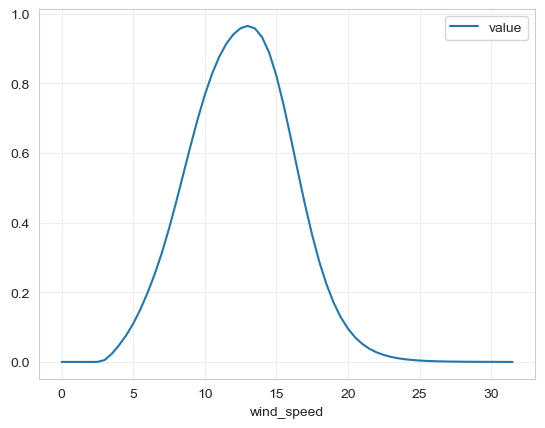

In [ ]:
df_vestas = df_turbine[df_turbine["turbine_type"] == "V90/2000"].iloc[0]
df_vestas["power_curve_wind_speeds"] = np.array(
    literal_eval(df_vestas["power_curve_wind_speeds"])
)
df_vestas["power_curve_values"] = np.array(
    literal_eval(df_vestas["power_curve_values"])
)
df_vestas["power_curve_values"] /= df_vestas["power_curve_values"].max()

print(
    f"Max in original: {df_vestas['power_curve_values'].max()}, for wind speed: {df_vestas['power_curve_wind_speeds'][df_vestas['power_curve_values'].argmax()]}"
)

df_vestas_smooth = pc.smooth_power_curve(
    pd.Series(df_vestas.power_curve_wind_speeds),
    pd.Series(df_vestas.power_curve_values),
    standard_deviation_method="turbulence_intensity",
    turbulence_intensity=0.fontsize_labels46,  # turbulence intensity taken from eq. 3-13 in Knorr (2016)
)

print(
    f"Max in smoothened version: {df_vestas_smooth['value'].max()}, for wind speed: {df_vestas_smooth['wind_speed'][df_vestas_smooth['value'].argmax()]}"
)

df_vestas_smooth.plot(x="wind_speed", y="value")
plt.show()

# Load wind speeds

In [8]:
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}

ds_wind_100m = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
    / "bias_corrected"
    / "3hr"
    / "wind100m.zarr",
    extent=extent,
)

ds_wind_150m = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
    / "bias_corrected"
    / "3hr"
    / "wind150m.zarr",
    extent=extent,
)

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/bias_correction_2024/share/proj failed


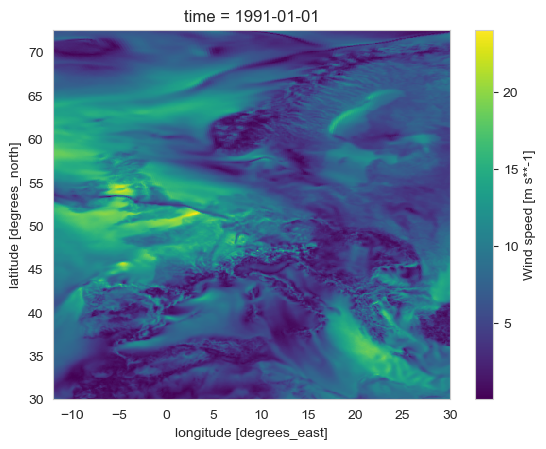

In [9]:
ds_wind_100m.ds_data.isel(time=0).wind100m.plot()

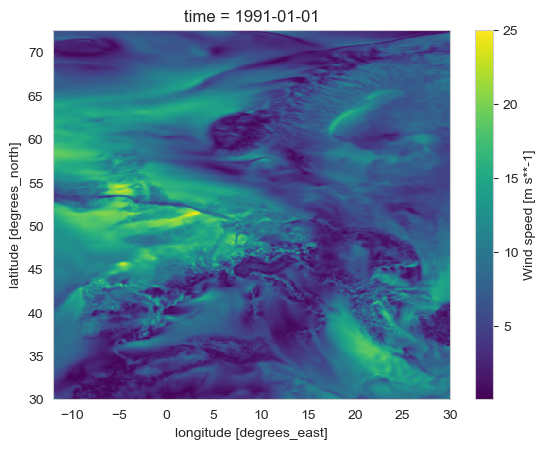

In [10]:
ds_wind_150m.ds_data.isel(time=0).wind150m.plot()

In [18]:
ds_wind100m_subset = ds_wind_100m.ds_data.sel(time=slice("2020", "2022"))
ds_wind150m_subset = ds_wind_150m.ds_data.sel(time=slice("2020", "2022"))

In [ ]:
da_alpha = compute_power_law_exponent(
    ds_wind100m_subset.wind100m, ds_wind150m_subset.wind150m, 100, 150
)

In [ ]:
turbine_type = "E-82/2300"
da_wind_hub_height = extrapolate_wind_speed(
    ds_wind100m_subset.wind100m, 100, ch_hub_heights[turbine_type], da_alpha
)

In [ ]:
# Assume power_curve_df is already sorted and aligned with 0.1 m/s resolution
power_table = power_curves_ch_smoothed[turbine_type][
    turbine_type.replace("/", "_")
].values
min_ws = power_curves_ch_smoothed[turbine_type].index.min()  # e.g. 3.0
max_ws = power_curves_ch_smoothed[turbine_type].index.max()  # e.g. 25.0
step = 0.01  # wind speed resolution (e.g., 0.01 m/s)


def fast_lookup(ws_array):
    # Initialize power output array
    power = np.zeros_like(ws_array, dtype=float)

    # Mask valid wind speeds within the power curve range
    valid = (ws_array >= min_ws) & (ws_array <= max_ws)

    # Compute indices for valid wind speeds
    idx = ((ws_array[valid] - min_ws) / step).astype(int)
    idx = np.clip(idx, 0, len(power_table) - 1)

    # Assign power values using fast array indexing
    power[valid] = power_table[idx]
    return power


# Apply to your xarray DataArray
normalized_power = xr.apply_ufunc(
    fast_lookup,
    da_wind_hub_height.round(2),
    input_core_dims=[["time", "lat", "lon"]],
    output_core_dims=[["time", "lat", "lon"]],
    output_dtypes=[float],
    vectorize=True,
    dask="parallelized",  # remove if you're not using dask
)

In [23]:
da_wind_power = compute_wind_power(
    da_wind_hub_height.round(2),
    power_curves_ch_smoothed[turbine_type][turbine_type.replace("/", "_")],
    turbine_type.replace("/", "_"),
    step=0.01,
    parallelized=True,
)

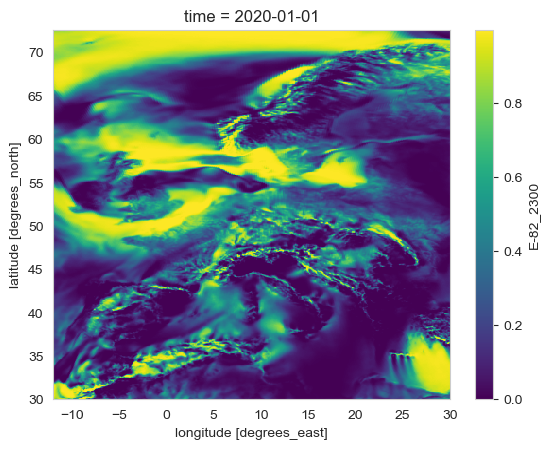

In [75]:
da_wind_power.isel(time=0).plot()

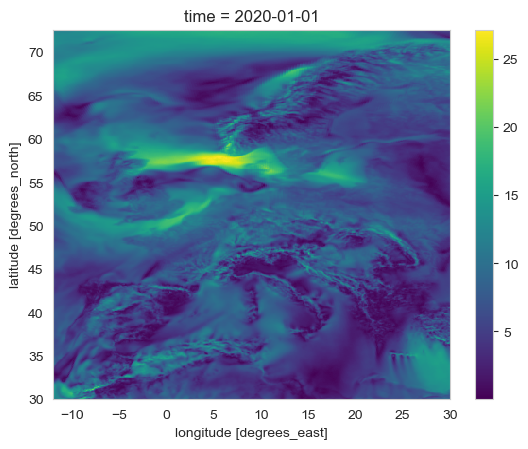

In [76]:
da_wind_hub_height.isel(time=0).plot()

# Load computed wind power potential

In [7]:
path_wind_power = (
    path_energy_ch
    / "wind_power"
    / f"wind_power_{climate_model_chain}_rcp85.zarr"
)
ds_wind_power_rcp85 = xr.open_zarr(path_wind_power, chunks="auto")
ds_wind_power_rcp26 = xr.open_zarr(
    path_wind_power.with_name(
        path_wind_power.name.replace("rcp85", "rcp26")
    ),
    chunks="auto",
)

In [8]:
ds_orog = sel_extent(
    xr.open_dataset(
        sorted(
            (
                path_data_processed
                / "cordex_processed"
                / f"{climate_model_chain}_{climate_scenario}"
                / "regridded"
                / "fx"
            ).glob("*.nc")
        )[0]
    ),
    extent_ch,
)

In [9]:
gdf_regions_ch = gpd.read_file(
    path_data_processed / "maps" / "regions_ch" / "PRODREG.shp"
).to_crs("EPSG:4326")
regions_ch = regionmask.from_geopandas(gdf_regions_ch, names="ProdregN_3")
regions_ch_mask = regions_ch.mask(ds_orog.orog)

In [10]:
# Define the reference and future periods
reference_period = slice("1991", "2020")
future_period = slice("2021", "2050")

## Visual inspection

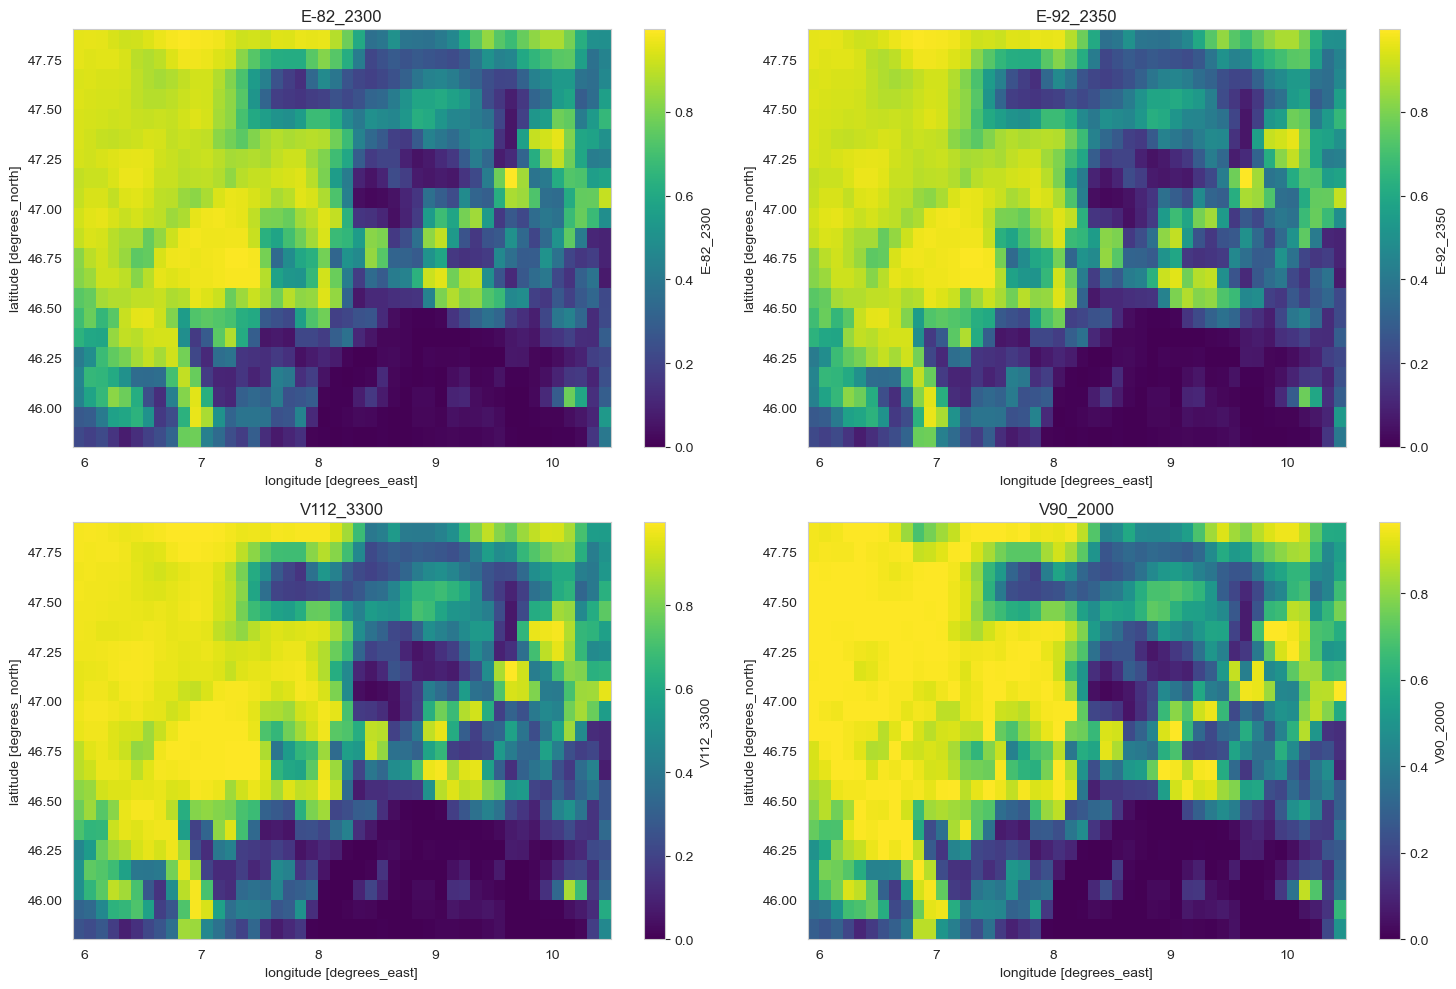

In [9]:
# Extract variable names from the dataset
variables = list(ds_wind.data_vars)

# Define the number of rows and columns for the grid
n_cols = 2
n_rows = (len(variables) + n_cols - 1) // n_cols  # Calculate rows needed

# Create subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
axes = axes.flatten()  # Flatten the axes array for easier indexing

# Loop through each variable and plot its first time step
for i, var in enumerate(variables):
    ax = axes[i]
    ds_wind[var].isel(time=0).plot(ax=ax)
    ax.set_title(var)

# Hide unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Adjust layout
plt.tight_layout()
plt.show()

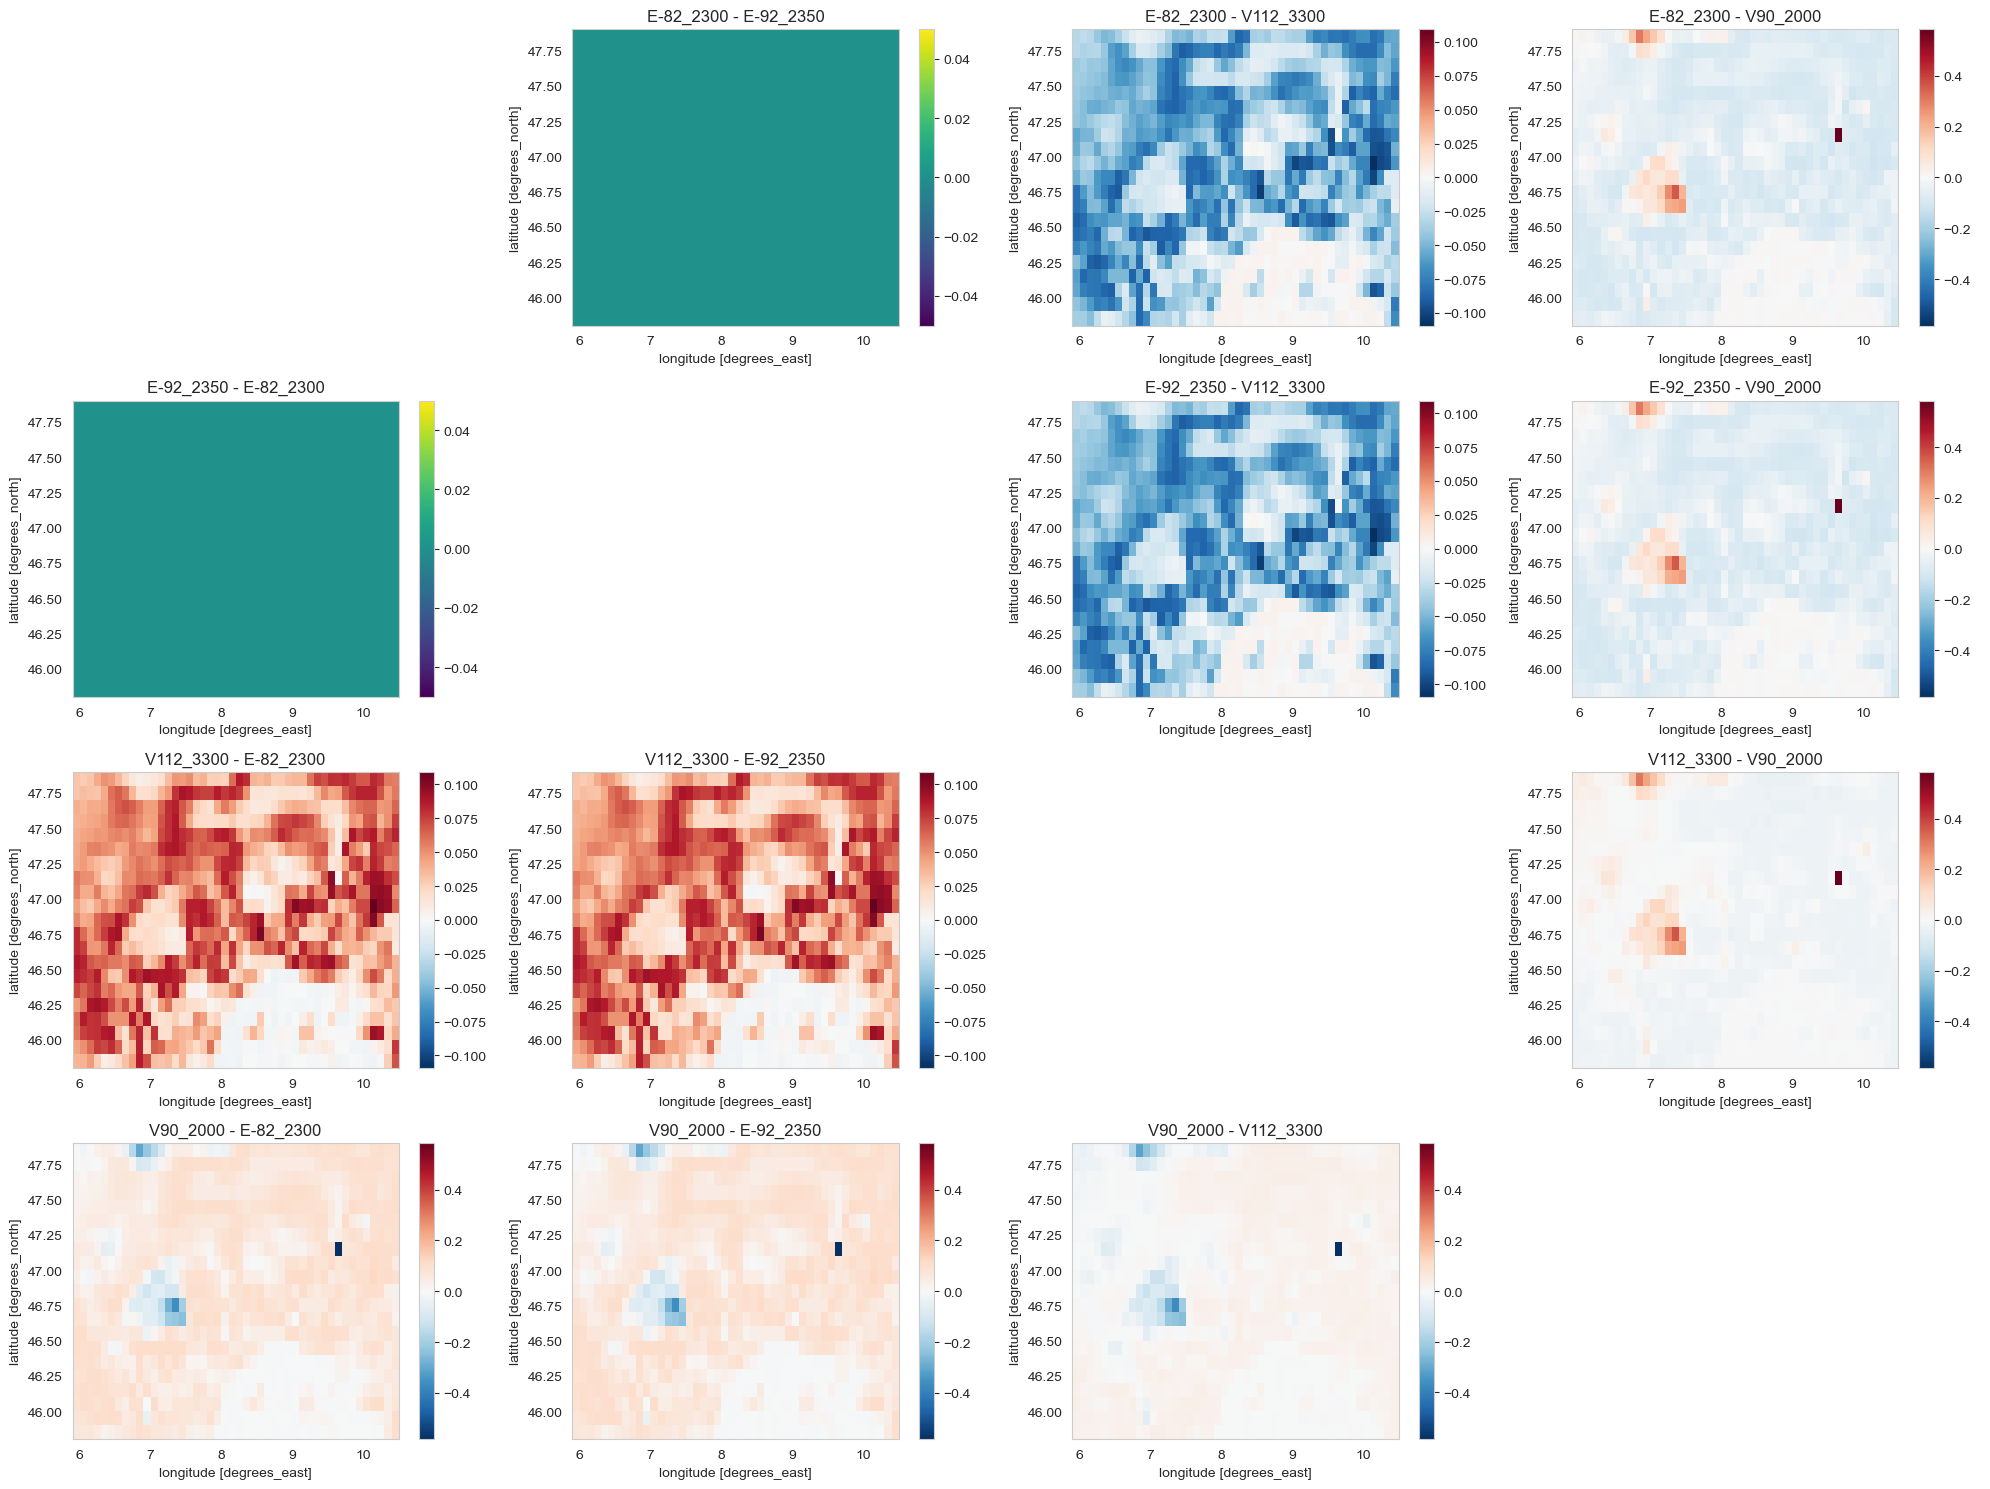

In [10]:
# Create subplots for differences
fig, axes = plt.subplots(len(variables), len(variables), figsize=(20, 15))

# Loop through each variable and compute differences
for i, var1 in enumerate(variables):
    for j, var2 in enumerate(variables):
        if i != j:
            # Compute the difference
            diff = ds_wind[var1].isel(time=0) - ds_wind[var2].isel(time=0)

            # Plot the difference
            ax = axes[i, j]
            diff.plot(ax=ax)
            ax.set_title(f"{var1} - {var2}")
        else:
            # Leave diagonal plots empty
            axes[i, j].axis("off")

# Adjust layout
plt.tight_layout()
plt.show()

## Wind power evolution over time and seasons

### Mean change

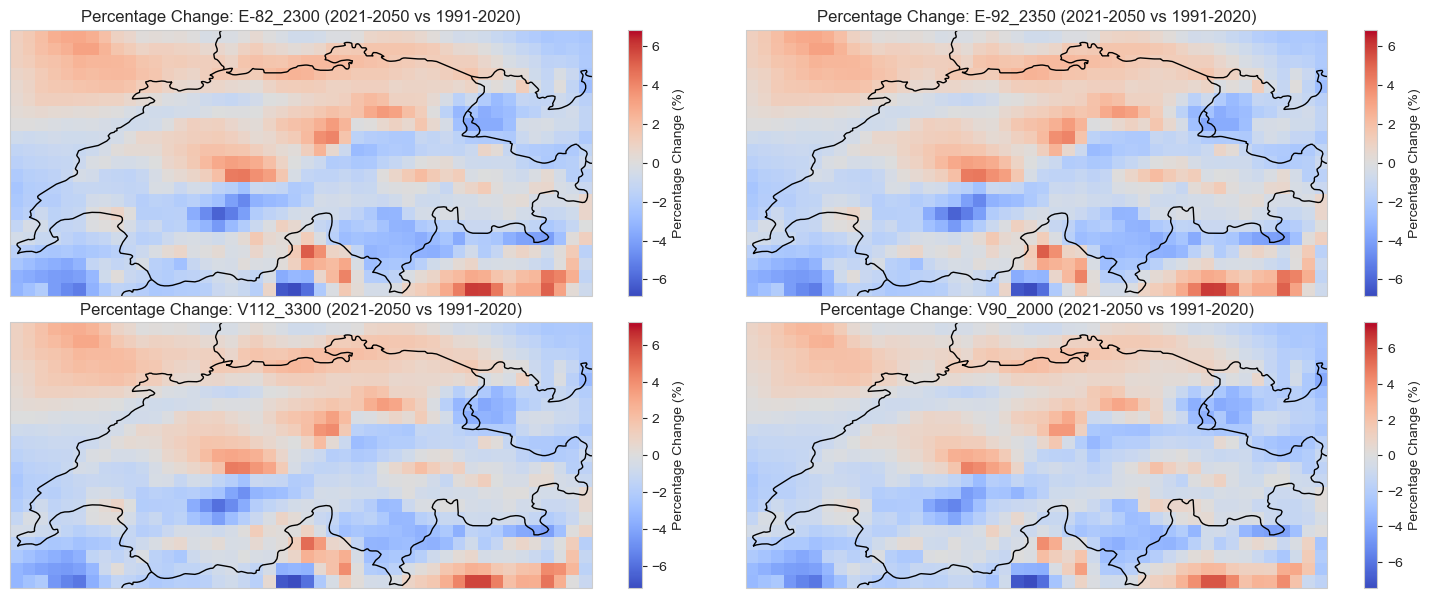

In [ ]:
# Calculate the mean wind power for each period
mean_reference = ds_wind.sel(time=reference_period).mean(dim="time")
mean_future = ds_wind.sel(time=future_period).mean(dim="time")

# Compute the difference between the future and reference periods
percentage_change = ((mean_future - mean_reference) / mean_reference) * 100

# Plot the percentage change for each turbine type
n_cols = 2
n_rows = (len(variables) + n_cols - 1) // n_cols  # Calculate rows needed

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, 3 * n_rows),
    subplot_kw={"projection": ccrs.PlateCarree()},
)
axes = axes.flatten()

for i, var in enumerate(variables):
    ax = axes[i]
    percentage_change[var].plot(
        ax=ax, cmap="coolwarm", cbar_kwargs={"label": "Percentage Change (%)"}
    )
    ax.set_title(f"Percentage Change: {var} (2021-2050 vs 1991-2020)")
    ax.add_feature(
        cfeature.BORDERS, linestyle="-", edgecolor="black"
    )  # Add country borders
    ax.add_feature(cfeature.COASTLINE, edgecolor="black")  # Add coastlines

# Hide unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

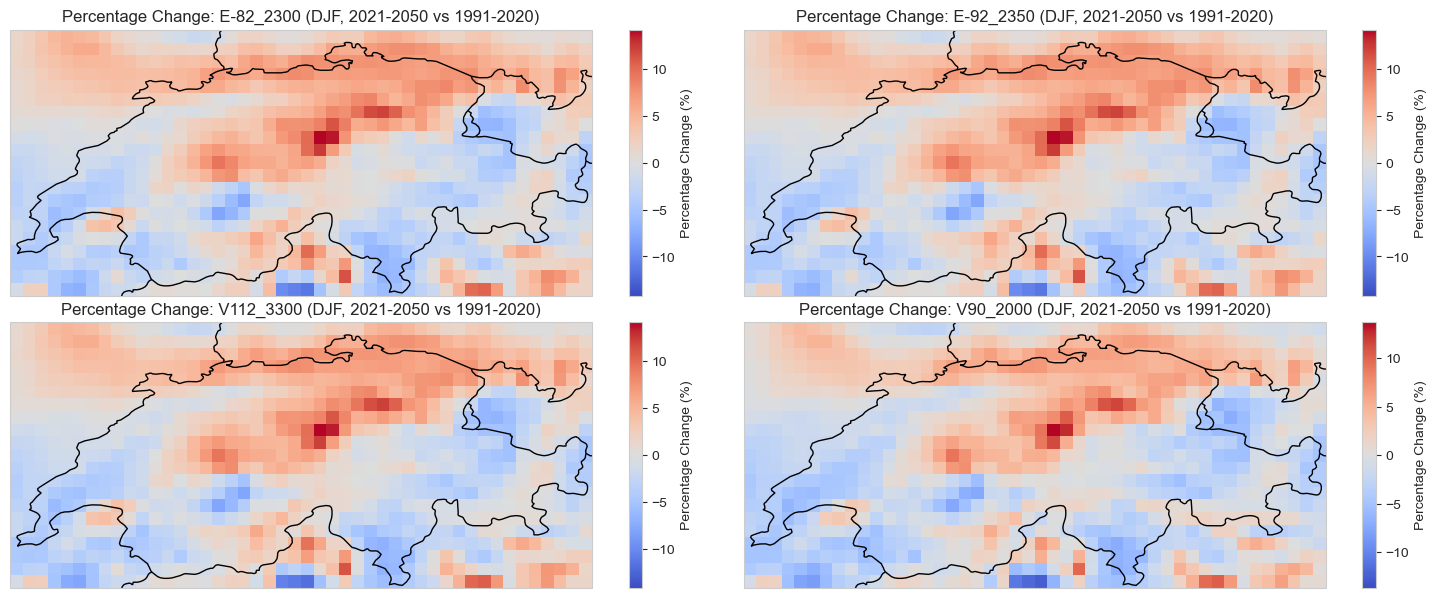

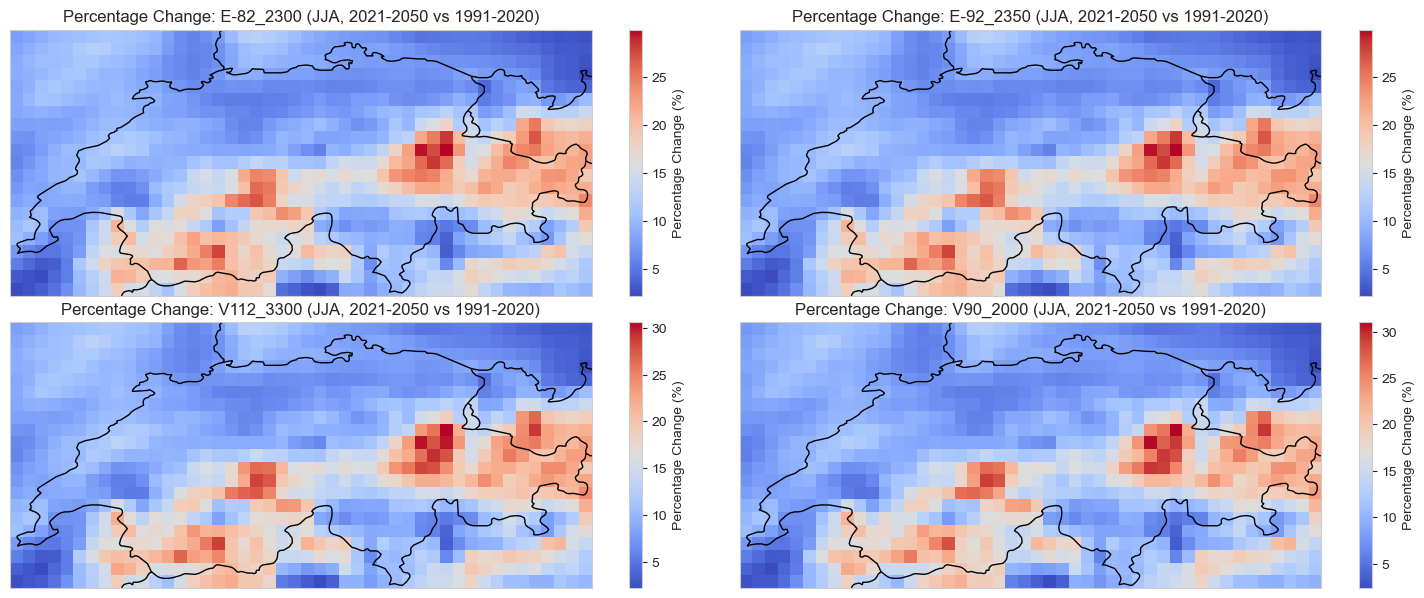

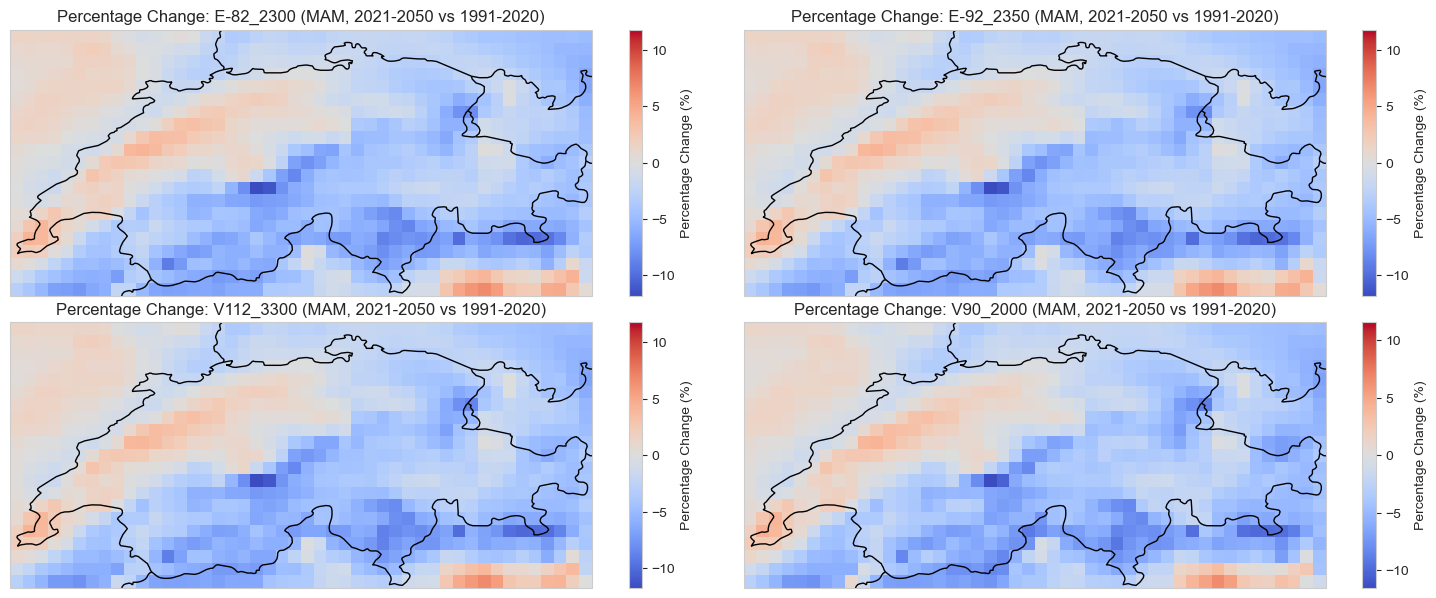

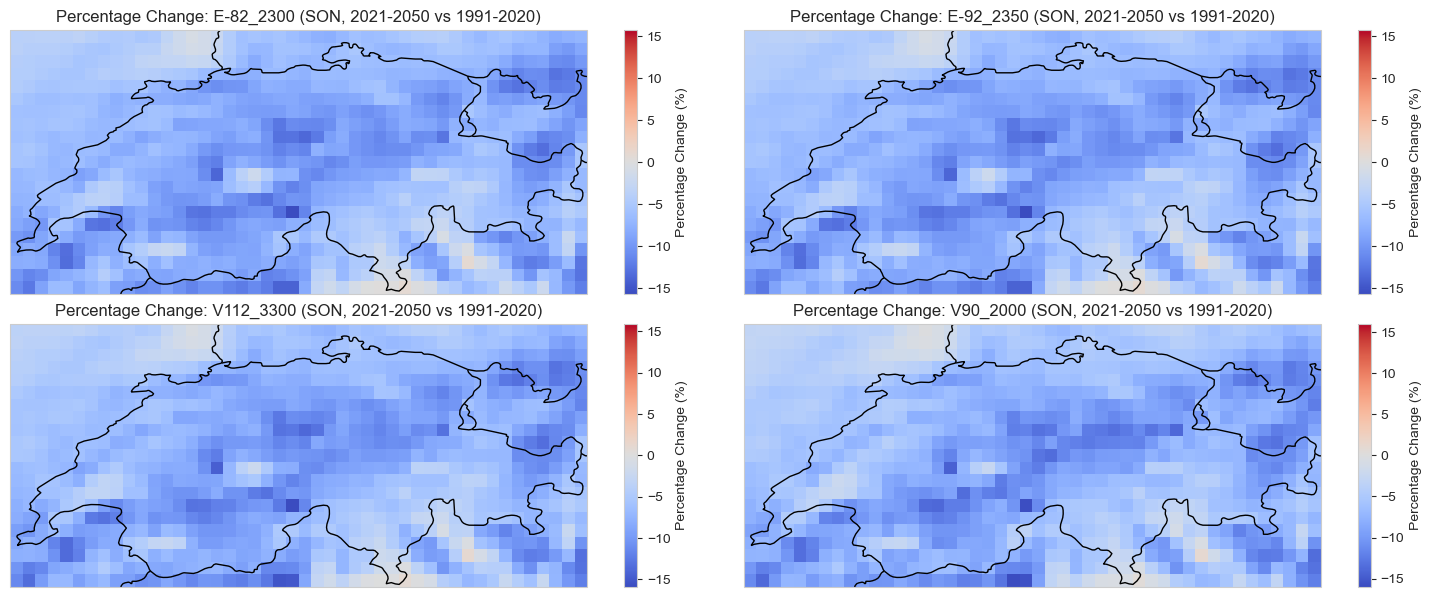

In [12]:
# Group data by season and calculate the mean for each season
seasonal_reference = (
    ds_wind.sel(time=reference_period).groupby("time.season").mean(dim="time")
)
seasonal_future = (
    ds_wind.sel(time=future_period).groupby("time.season").mean(dim="time")
)

# Compute the percentage change for each season
seasonal_percentage_change = (
    (seasonal_future - seasonal_reference) / seasonal_reference
) * 100

# Plot the percentage change for each turbine type and season
n_cols = 2
n_rows = (len(variables) + n_cols - 1) // n_cols  # Calculate rows needed

for season in seasonal_percentage_change.season.values:
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(15, 3 * n_rows),
        subplot_kw={"projection": ccrs.PlateCarree()},
    )
    axes = axes.flatten()

    for i, var in enumerate(variables):
        ax = axes[i]
        seasonal_percentage_change[var].sel(season=season).plot(
            ax=ax, cmap="coolwarm", cbar_kwargs={"label": "Percentage Change (%)"}
        )
        ax.set_title(f"Percentage Change: {var} ({season}, 2021-2050 vs 1991-2020)")
        ax.add_feature(
            cfeature.BORDERS, linestyle="-", edgecolor="black"
        )  # Add country borders
        ax.add_feature(cfeature.COASTLINE, edgecolor="black")  # Add coastlines

    # Hide unused subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

In [ ]:
ds_wind.sel(time=reference_period).resample(time="1D").mean(dim="time").groupby(
    "time.month"
).mean()

<xarray.Dataset> Size: 372kB
Dimensions:    (month: 12, lat: 21, lon: 46)
Coordinates:
  * lat        (lat) float64 168B 45.85 45.95 46.05 46.15 ... 47.65 47.75 47.85
  * lon        (lon) float64 368B 5.95 6.05 6.15 6.25 ... 10.25 10.35 10.45
  * month      (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
Data variables:
    E-82_2300  (month, lat, lon) float64 93kB dask.array<chunksize=(12, 21, 46), meta=np.ndarray>
    E-92_2350  (month, lat, lon) float64 93kB dask.array<chunksize=(12, 21, 46), meta=np.ndarray>
    V112_3300  (month, lat, lon) float64 93kB dask.array<chunksize=(12, 21, 46), meta=np.ndarray>
    V90_2000   (month, lat, lon) float64 93kB dask.array<chunksize=(12, 21, 46), meta=np.ndarray>

In [ ]:
selected_turbine = "E-82_2300"
# Calculate the mean of monthly sums for the reference and future periods over all lat/lon
mean_monthly_reference_agg = (
    ds_wind.sel(time=reference_period)
    .resample(time="1D")
    .mean(dim="time")
    .groupby("time.month")
    .mean()
    .mean(dim=["lat", "lon"])
)
mean_monthly_future_agg = (
    ds_wind.sel(time=future_period)
    .resample(time="1D")
    .mean(dim="time")
    .groupby("time.month")
    .mean()
    .mean(dim=["lat", "lon"])
)

# Plot the results
plt.figure(figsize=(10, 6))
mean_monthly_reference_agg[selected_turbine].plot(
    label="Reference Period (1991-2020)", marker="o"
)
mean_monthly_future_agg[selected_turbine].plot(
    label="Future Period (2021-2050)", marker="x"
)
plt.title("Mean Monthly Sum Aggregated Over All Lat/Lon")
plt.ylabel("Mean Monthly PV Output (kWh)")
plt.xlabel("Month")
plt.xticks(
    ticks=mean_monthly_reference_agg["month"].values,
    labels=mean_monthly_reference_agg["month"].values,
)
plt.legend()
plt.show()

KeyboardInterrupt: 

<Figure size 1000x600 with 0 Axes>

### Variability

In [11]:
# Compute standard deviations for the reference and future periods
std_reference = ds_wind.sel(time=reference_period).std()
std_future = ds_wind.sel(time=future_period).std()

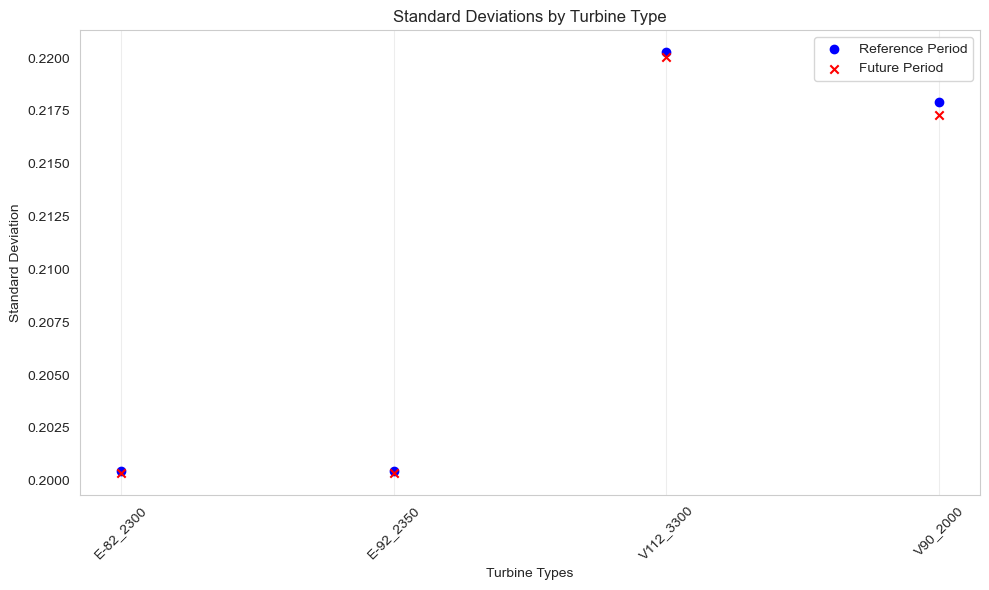

In [12]:
# Extract variables and their standard deviations
variables = list(std_reference.data_vars)
std_ref_values = [std_reference[var].values for var in variables]
std_fut_values = [std_future[var].values for var in variables]

# Create a scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(
    variables, std_ref_values, label="Reference Period", color="blue", marker="o"
)
plt.scatter(variables, std_fut_values, label="Future Period", color="red", marker="x")

# Add labels, legend, and title
plt.xlabel("Turbine Types")
plt.ylabel("Standard Deviation")
plt.title("Standard Deviations by Turbine Type")
plt.xticks(rotation=45)
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [13]:
# 1. Compute the coefficient of variation (CV) for reference and future periods
cv_reference = std_reference / ds_wind.sel(time=reference_period).mean()
cv_future = std_future / ds_wind.sel(time=future_period).mean()

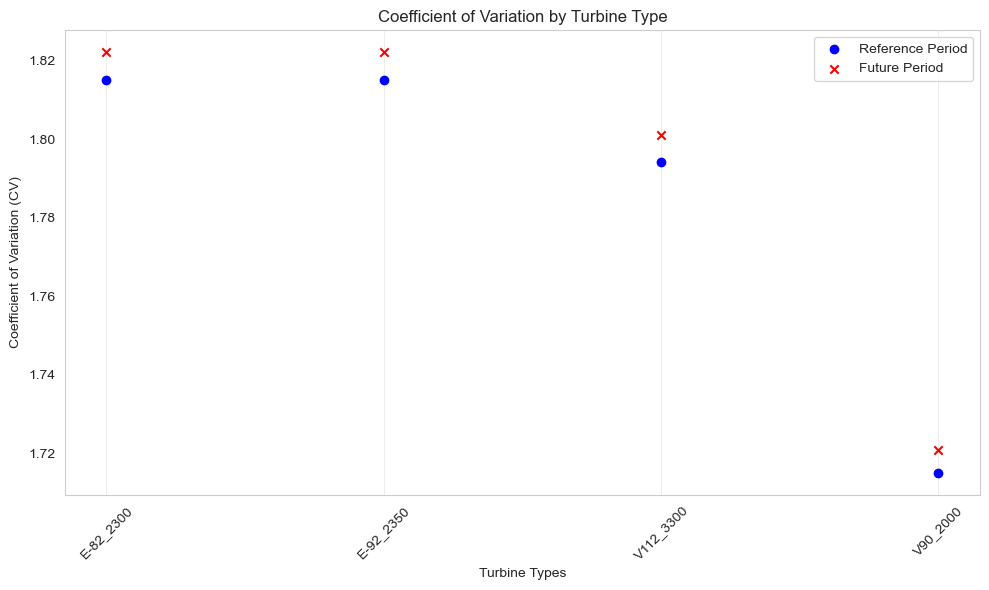

In [14]:
# Extract variables and their standard deviations
variables = list(std_reference.data_vars)
cv_ref_values = [cv_reference[var].values for var in variables]
cv_fut_values = [cv_future[var].values for var in variables]

# Create a scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(
    variables, cv_ref_values, label="Reference Period", color="blue", marker="o"
)
plt.scatter(variables, cv_fut_values, label="Future Period", color="red", marker="x")

# Add labels, legend, and title
plt.xlabel("Turbine Types")
plt.ylabel("Coefficient of Variation (CV)")
plt.title("Coefficient of Variation by Turbine Type")
plt.xticks(rotation=45)
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [ ]:
# 3. Perform Levene's test to compare variances
from scipy.stats import levene

for var in variables:
    reference_data = ds_wind[var].sel(time=reference_period).mean().values.flatten()
    future_data = ds_wind[var].sel(time=future_period).mean().values.flatten()

    stat, p_value = levene(reference_data, future_data)
    print(f"Levene's test for {var}: Statistic={stat}, p-value={p_value}")
    if p_value < 0.05:
        print(f"Variability for {var} is significantly different between periods.")
    else:
        print(f"No significant difference in variability for {var}.")

Levene's test for E-82_2300: Statistic=247.80840285738836, p-value=7.803251214733686e-56
Variability for E-82_2300 is significantly different between periods.
Levene's test for E-92_2350: Statistic=247.80840285738836, p-value=7.803251214733686e-56
Variability for E-92_2350 is significantly different between periods.
Levene's test for V112_3300: Statistic=311.00494021423987, p-value=1.3193766843489674e-69
Variability for V112_3300 is significantly different between periods.
Levene's test for V90_2000: Statistic=574.2573087604862, p-value=6.6597187640450424e-127
Variability for V90_2000 is significantly different between periods.


In [ ]:
# 3. Perform Levene's test to compare variances
from scipy.stats import levene

for var in variables:
    reference_data = (
        ds_wind[var]
        .sel(time=reference_period)
        .mean(dim=["lat", "lon"])
        .values.flatten()
    )
    future_data = (
        ds_wind[var].sel(time=future_period).mean(dim=["lat", "lon"]).values.flatten()
    )

    stat, p_value = levene(reference_data, future_data)
    print(f"Levene's test for {var}: Statistic={stat}, p-value={p_value}")
    if p_value < 0.05:
        print(f"Variability for {var} is significantly different between periods.")
    else:
        print(f"No significant difference in variability for {var}.")

Levene's test for E-82_2300: Statistic=0.1313017095252728, p-value=0.7170866186126708
No significant difference in variability for E-82_2300.
Levene's test for E-92_2350: Statistic=0.1313017095252728, p-value=0.7170866186126708
No significant difference in variability for E-92_2350.
Levene's test for V112_3300: Statistic=0.1121757849537533, p-value=0.7376809046417125
No significant difference in variability for V112_3300.
Levene's test for V90_2000: Statistic=0.010294737227240912, p-value=0.9191830560155253
No significant difference in variability for V90_2000.


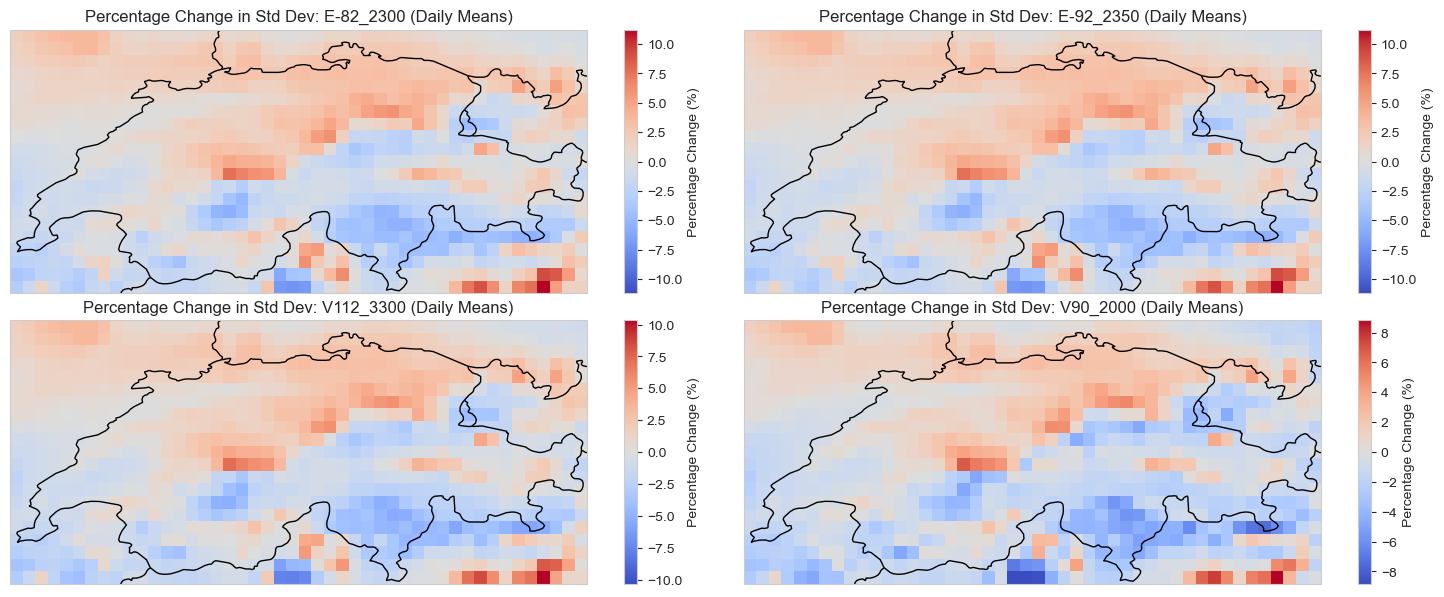

In [ ]:
# Compute daily means
ds_daily_mean = ds_wind.resample(time="1D").mean()

# Compute standard deviations for the reference and future periods
std_reference_daily = ds_daily_mean.sel(time=reference_period).std(dim="time")
std_future_daily = ds_daily_mean.sel(time=future_period).std(dim="time")

# Compute the percentage change
std_percentage_change_daily = (
    (std_future_daily - std_reference_daily) / std_reference_daily
) * 100

# Plot the percentage change for each turbine type
n_cols = 2
n_rows = (len(variables) + n_cols - 1) // n_cols  # Calculate rows needed

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, 3 * n_rows),
    subplot_kw={"projection": ccrs.PlateCarree()},
)
axes = axes.flatten()

for i, var in enumerate(variables):
    ax = axes[i]
    std_percentage_change_daily[var].plot(
        ax=ax, cmap="coolwarm", cbar_kwargs={"label": "Percentage Change (%)"}
    )
    ax.set_title(f"Percentage Change in Std Dev: {var} (Daily Means)")
    ax.add_feature(cfeature.BORDERS, linestyle="-", edgecolor="black")
    ax.add_feature(cfeature.COASTLINE, edgecolor="black")

# Hide unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Upper and lower quantiles

In [19]:
selected_turbine = "E-82_2300"

In [16]:
ds_daily_mean = ds_wind.resample(time="1D").mean().compute()
ds_daily_mean

<xarray.Dataset> Size: 1GB
Dimensions:    (time: 39812, lat: 21, lon: 46)
Coordinates:
  * lat        (lat) float64 168B 45.85 45.95 46.05 46.15 ... 47.65 47.75 47.85
  * lon        (lon) float64 368B 5.95 6.05 6.15 6.25 ... 10.25 10.35 10.45
  * time       (time) datetime64[ns] 318kB 1991-01-01 1991-01-02 ... 2099-12-31
Data variables:
    E-82_2300  (time, lat, lon) float64 308MB 0.1111 0.06419 ... 0.3977 0.4868
    E-92_2350  (time, lat, lon) float64 308MB 0.1111 0.06419 ... 0.3977 0.4868
    V112_3300  (time, lat, lon) float64 308MB 0.1283 0.07286 ... 0.4541 0.5555
    V90_2000   (time, lat, lon) float64 308MB 0.146 0.08148 ... 0.4852 0.5836

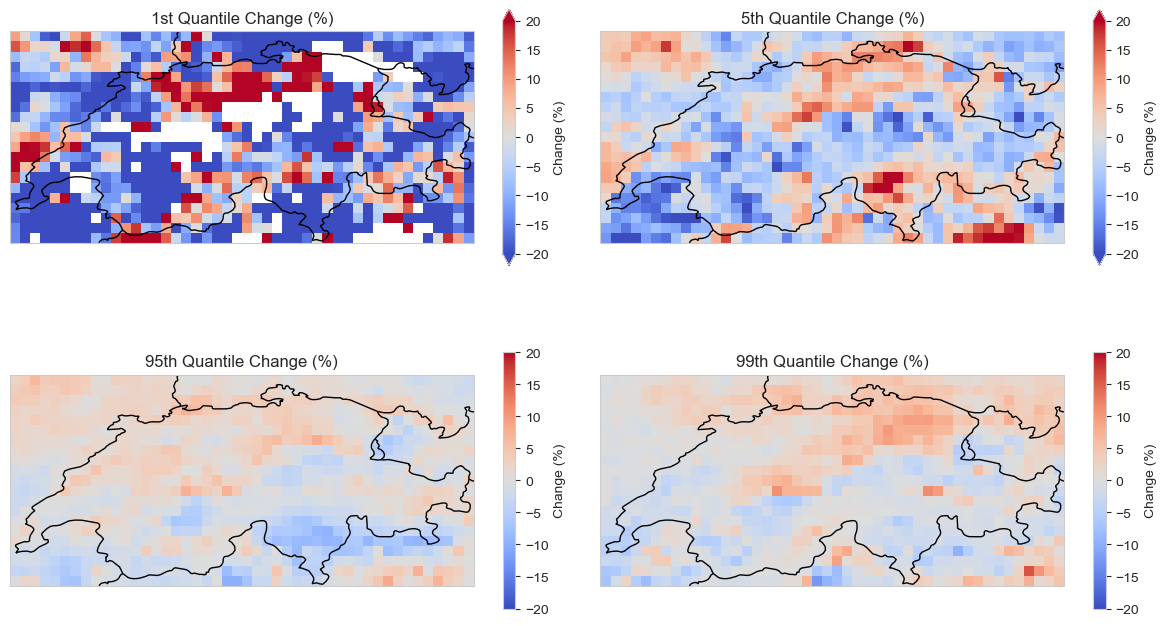

In [ ]:
quantiles = [0.01, 0.05, 0.95, 0.99]
# Calculate the 5th and 95th quantiles for the reference period
quantiles_reference = (
    ds_daily_mean[selected_turbine]
    .sel(time=reference_period)
    .quantile(quantiles, dim="time")
)

# Calculate the 5th and 95th quantiles for the future period
quantiles_future = (
    ds_daily_mean[selected_turbine]
    .sel(time=future_period)
    .quantile(quantiles, dim="time")
)

# Compute the mean change for the 5th and 95th quantiles
mean_change_quantiles = (
    (quantiles_future - quantiles_reference) / quantiles_reference * 100
)

# Plot the mean changes for the 5th and 95th quantiles
fig, axes = plt.subplots(
    2, 2, figsize=(12, 8), subplot_kw={"projection": ccrs.PlateCarree()}
)
axes = axes.flatten()

for ax, quantile, title in zip(
    axes,
    quantiles,
    [
        "1st Quantile Change (%)",
        "5th Quantile Change (%)",
        "95th Quantile Change (%)",
        "99th Quantile Change (%)",
    ],
):
    mean_change_quantiles.sel(quantile=quantile).plot(
        ax=ax,
        vmin=-20,
        vmax=20,
        cmap="coolwarm",
        cbar_kwargs={"label": "Change (%)", "shrink": 0.6},
    )
    ax.set_title(title)
    ax.add_feature(cfeature.BORDERS, linestyle="-", edgecolor="black")
    ax.add_feature(cfeature.COASTLINE, edgecolor="black")

plt.tight_layout()
plt.show()

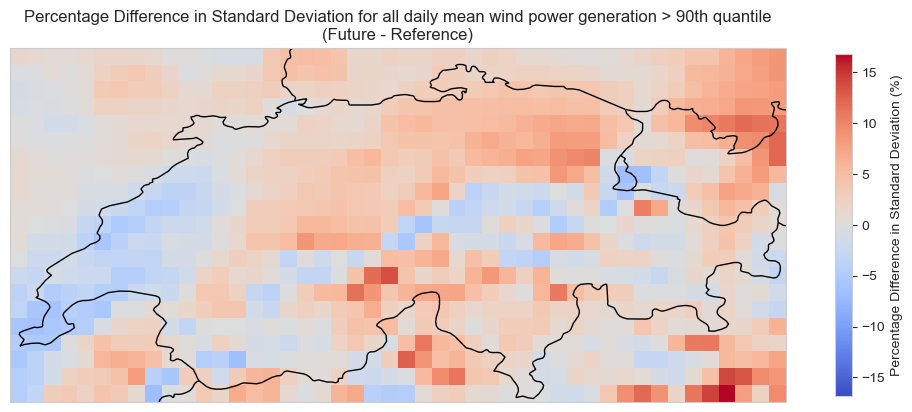

In [ ]:
# Define the quantile threshold
quantile_threshold = 0.90

# Select values above the quantile threshold for the reference period
above_quantile_reference = (
    ds_daily_mean[selected_turbine]
    .sel(time=reference_period)
    .where(
        ds_daily_mean[selected_turbine].sel(time=reference_period)
        > ds_daily_mean[selected_turbine]
        .sel(time=reference_period)
        .quantile(quantile_threshold, dim="time")
    )
)

# Compute the standard deviation for the reference period
std_above_quantile_reference = above_quantile_reference.std(dim="time")

# Select values above the quantile threshold for the future period
above_quantile_future = (
    ds_daily_mean[selected_turbine]
    .sel(time=future_period)
    .where(
        ds_daily_mean[selected_turbine].sel(time=future_period)
        > ds_daily_mean[selected_turbine]
        .sel(time=future_period)
        .quantile(quantile_threshold, dim="time")
    )
)

# Compute the standard deviation for the future period
std_above_quantile_future = above_quantile_future.std(dim="time")

# Compute the difference between the standard deviations
std_percentage_difference = (
    (std_above_quantile_future - std_above_quantile_reference)
    / std_above_quantile_reference
) * 100

# Plot the percentage difference
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={"projection": ccrs.PlateCarree()})

std_percentage_difference.plot(
    ax=ax,
    cmap="coolwarm",
    cbar_kwargs={
        "label": "Percentage Difference in Standard Deviation (%)",
        "shrink": 0.6,
    },
)
ax.set_title(
    "Percentage Difference in Standard Deviation for all daily mean wind power generation > 90th quantile\n(Future - Reference)"
)
ax.add_feature(cfeature.BORDERS, linestyle="-", edgecolor="black")
ax.add_feature(cfeature.COASTLINE, edgecolor="black")

plt.tight_layout()
plt.show()

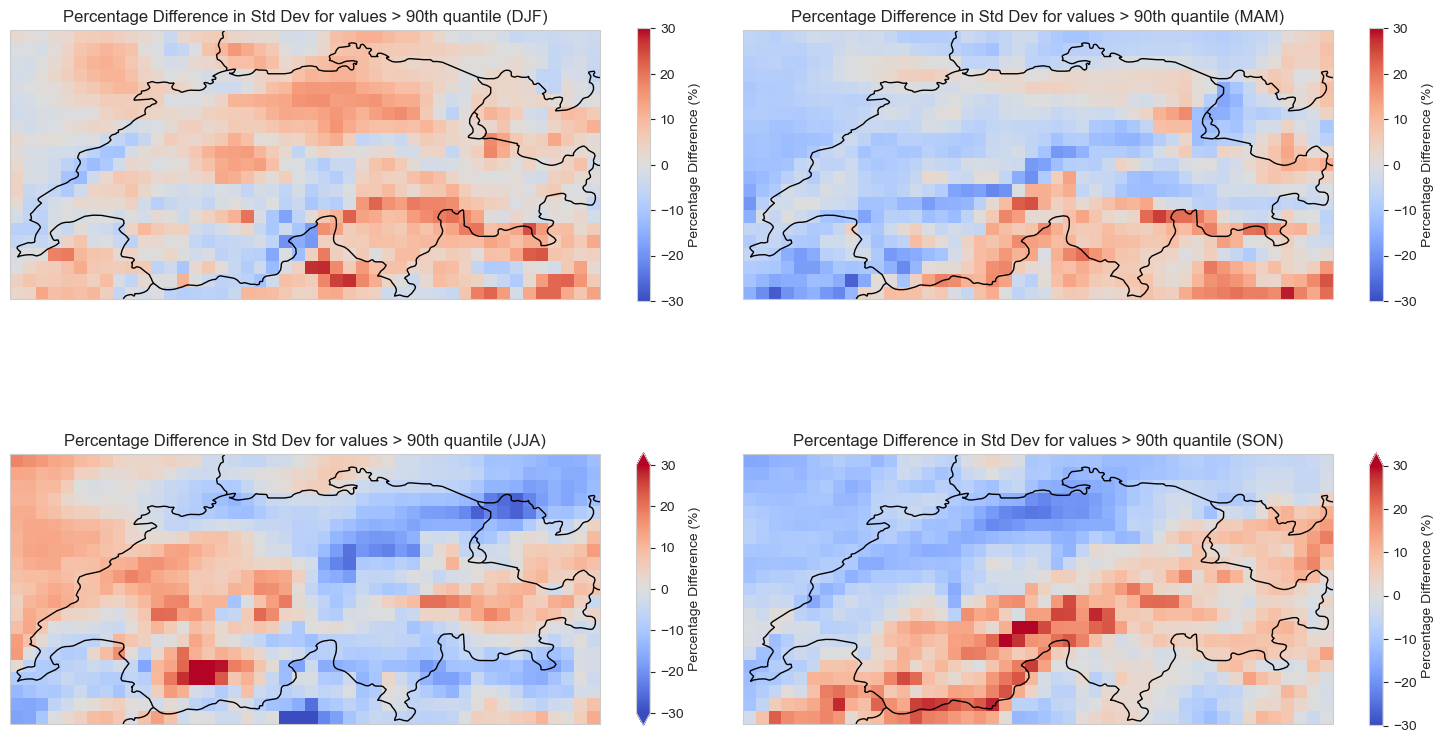

In [ ]:
# Define the quantile threshold
quantile_threshold = 0.90


def compute_above_quantile_seasonal(ds, var, time_period, q):
    ds_period = ds[var].sel(time=time_period)
    results = []

    for season in ["DJF", "MAM", "JJA", "SON"]:
        ds_season = ds_period.sel(time=ds_period["time.season"] == season)

        # Quantile over time for each grid cell
        threshold = ds_season.quantile(q, dim="time")

        # Mask values above the threshold
        masked = ds_season.where(ds_season > threshold)

        # Add season as coordinate for stacking later
        masked = masked.expand_dims(season=[season])
        results.append(masked)

    return xr.concat(results, dim="season")


# Apply to reference and future
above_quantile_reference_seasonal = compute_above_quantile_seasonal(
    ds_daily_mean, selected_turbine, reference_period, quantile_threshold
)
above_quantile_future_seasonal = compute_above_quantile_seasonal(
    ds_daily_mean, selected_turbine, future_period, quantile_threshold
)

# Compute the standard deviation for each season
std_above_quantile_reference_seasonal = above_quantile_reference_seasonal.std(
    dim="time"
)
std_above_quantile_future_seasonal = above_quantile_future_seasonal.std(dim="time")

# Compute the percentage difference in standard deviation for each season
std_percentage_difference_seasonal = (
    (std_above_quantile_future_seasonal - std_above_quantile_reference_seasonal)
    / std_above_quantile_reference_seasonal
) * 100

# Plot the percentage difference for each season
fig, axes = plt.subplots(
    2, 2, figsize=(15, 10), subplot_kw={"projection": ccrs.PlateCarree()}
)
axes = axes.flatten()

for i, season in enumerate(std_percentage_difference_seasonal.season.values):
    ax = axes[i]
    std_percentage_difference_seasonal.sel(season=season).plot(
        ax=ax,
        vmin=-30,
        vmax=30,
        cmap="coolwarm",
        cbar_kwargs={"label": "Percentage Difference (%)", "shrink": 0.5},
    )
    ax.set_title(
        f"Percentage Difference in Std Dev for values > 90th quantile ({season})"
    )
    ax.add_feature(cfeature.BORDERS, linestyle="-", edgecolor="black")
    ax.add_feature(cfeature.COASTLINE, edgecolor="black")

plt.tight_layout()
plt.show()

## EGU Plots

In [11]:
selected_turbine = "E-82_2300"
# Calculate the mean values for the reference period
mean_reference = ds_wind_power_rcp85[selected_turbine].sel(time=reference_period).mean(dim="time")

# Calculate the mean values for the future period
mean_future = ds_wind_power_rcp85[selected_turbine].sel(time=future_period).mean(dim="time")

# Calculate the percentage change
percentage_change = ((mean_future - mean_reference) / mean_reference) * 100

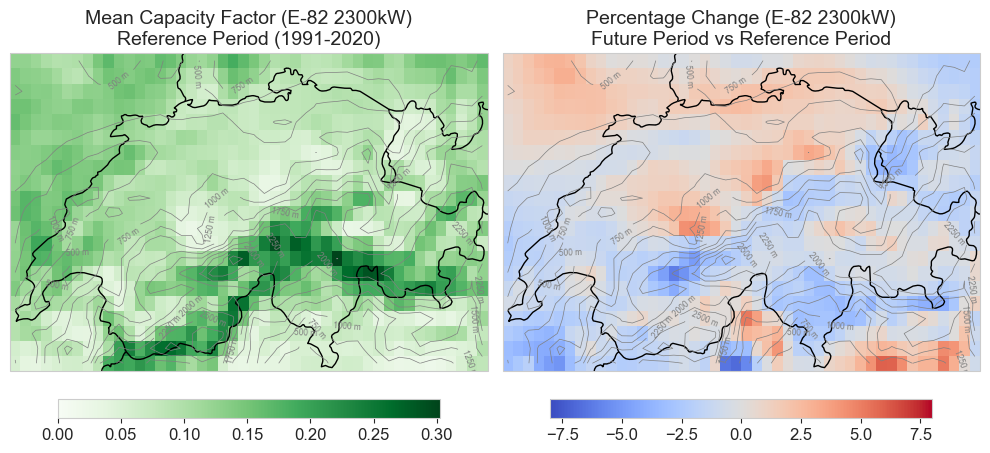

In [20]:
fontsize_ticks = 12
fontsize_labels = 14
fontsize_title = 14

# Define Mercator projection centered roughly over Switzerland
proj = ccrs.Mercator(central_longitude=8.0)

fig, axes = plt.subplots(1, 2, figsize=(10, 6), subplot_kw={"projection": proj})

# Helper to configure map features and extent
def setup_axes(ax, title):
    ax.set_title(title, fontsize=fontsize_labels)
    ax.set_extent([extent_ch["lon_min"], extent_ch["lon_max"],
                   extent_ch["lat_min"], extent_ch["lat_max"]],
                  crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.BORDERS, linestyle="-", edgecolor="black")
    ax.add_feature(cfeature.COASTLINE, edgecolor="black")
    ax.add_feature(cfeature.LAND, facecolor="lightgray")
    ax.add_feature(cfeature.OCEAN, facecolor="lightblue")

# Plot mean capacity factor
plot = mean_reference.plot(
    ax=axes[0],
    cmap="Greens",
    transform=ccrs.PlateCarree(),
    cbar_kwargs={
        "label": "Mean Capacity Factor",
        "shrink": 0.8,
        "orientation": "horizontal",
        "pad": 0.05,
        "aspect": 20,
    },
    vmin=0,
)
# Modify colorbar font sizes
colorbar = plot.colorbar
colorbar.ax.tick_params(labelsize=fontsize_ticks)  # Set tick label size
colorbar.set_label(colorbar.ax.get_ylabel(), fontsize=fontsize_labels)  # Set label font size

title_selected_var = selected_turbine.replace("_", " ").title() + "kW"
setup_axes(axes[0], f"Mean Capacity Factor ({title_selected_var})\nReference Period (1991-2020)")

# Plot percentage change
plot = percentage_change.plot(
    ax=axes[1],
    cmap="coolwarm",
    transform=ccrs.PlateCarree(),
    cbar_kwargs={
        "label": "Percentage Change (%)",
        "shrink": 0.8,
        "orientation": "horizontal",
        "pad": 0.05,
        "aspect": 20,
    },
    vmin=-8,
    vmax=8,
)
# Modify colorbar font sizes
colorbar = plot.colorbar
colorbar.ax.tick_params(labelsize=fontsize_ticks)  # Set tick label size
colorbar.set_label(colorbar.ax.get_ylabel(), fontsize=fontsize_labels)  # Set label font size

setup_axes(axes[1], f"Percentage Change ({title_selected_var})\nFuture Period vs Reference Period")

# Add elevation contours to both maps
for ax in axes:
    cs = ax.contour(
        ds_orog.lon,
        ds_orog.lat,
        ds_orog.orog,
        levels=10,
        colors="grey",
        linewidths=0.5,
        transform=ccrs.PlateCarree(),
    )
    ax.clabel(cs, inline=True, fontsize=6, fmt="%d m")

for ax in axes:
    ax.tick_params(axis="both", which="major", labelsize=fontsize_labels)
    ax.tick_params(axis="both", which="minor", labelsize=fontsize_labels)

plt.tight_layout()

path_save_fig = path_figs / "wind"
path_save_fig.mkdir(parents=True, exist_ok=True)

plt.savefig(
    path_save_fig
    / f"{climate_model_chain}_{climate_scenario}_{selected_turbine}_mean_capacity_factor_percentage_change.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

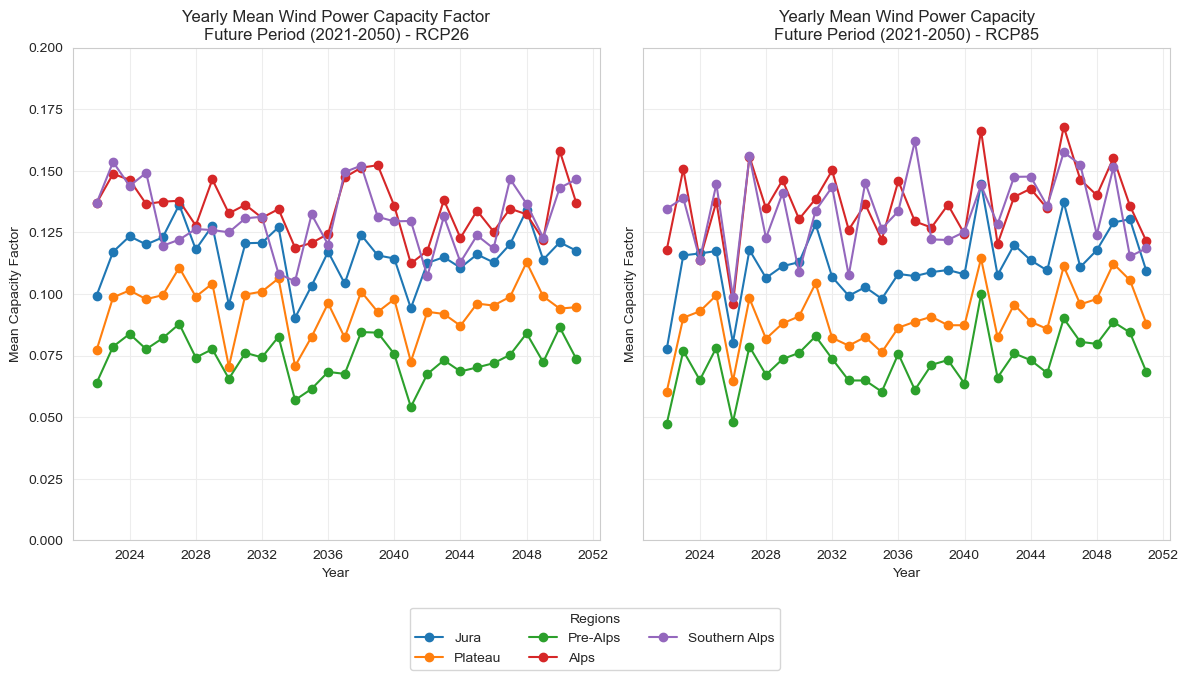

In [14]:
# Aggregate on a yearly level for each region for the future period (rcp85)
yearly_aggregated_future_rcp85 = (
    ds_wind_power_rcp85.sel(time=future_period)
    .resample(time="1YE")
    .mean()
    .groupby(regions_ch_mask)
    .mean(dim=("lat", "lon"))
)
yearly_aggregated_future_rcp85["mask"] = gdf_regions_ch["ProdregN_3"].values

# Aggregate on a yearly level for each region for the future period (rcp26)
yearly_aggregated_future_rcp26 = (
    ds_wind_power_rcp26.sel(time=future_period)
    .resample(time="1YE")
    .mean()
    .groupby(regions_ch_mask)
    .mean(dim=("lat", "lon"))
)
yearly_aggregated_future_rcp26["mask"] = gdf_regions_ch["ProdregN_3"].values

# Plot the time series for each region
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)


# Plot for rcp26
for region in yearly_aggregated_future_rcp26["mask"].values:
    yearly_aggregated_future_rcp26.sel(mask=region)[selected_turbine].plot(
        ax=axes[0], label=region, marker="o"
    )
axes[0].set_title("Yearly Mean Wind Power Capacity Factor\nFuture Period (2021-2050) - RCP26")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Mean Capacity Factor")
axes[0].set_ylim(0, 0.2)

# Plot for rcp85
for region in yearly_aggregated_future_rcp85["mask"].values:
    yearly_aggregated_future_rcp85.sel(mask=region)[selected_turbine].plot(
        ax=axes[1], label=region, marker="o"
    )
axes[1].set_title("Yearly Mean Wind Power Capacity\nFuture Period (2021-2050) - RCP85")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Mean Capacity Factor")
axes[1].set_ylim(0, 0.2)

# Add a common legend outside the plots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.01),
    ncol=3,
    title="Regions",
)

plt.tight_layout()
plt.show()

/tmp/ipykernel_50462/29505776.py:68: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_labels, rotation=0, ha="center", fontsize=fontsize_labels)


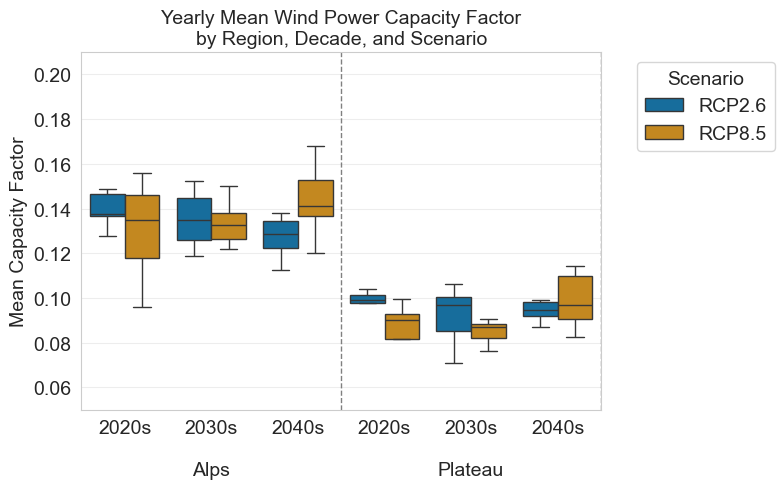

In [17]:
fontsize_labels = 14
fontsize_title = 14
colors = sns.color_palette("colorblind")[0:2]

# Add RCP26 data to the DataFrame
yearly_aggregated_future_rcp26 = yearly_aggregated_future_rcp26.assign_coords(
    decade=(yearly_aggregated_future_rcp26["time"].dt.year // 10) * 10
)
df_rcp26 = yearly_aggregated_future_rcp26[selected_turbine].to_dataframe().reset_index()
df_rcp26["scenario"] = "RCP2.6"

# Add RCP85 data to the DataFrame
yearly_aggregated_future_rcp85 = yearly_aggregated_future_rcp85.assign_coords(
    decade=(yearly_aggregated_future_rcp85["time"].dt.year // 10) * 10
)
df_rcp85 = yearly_aggregated_future_rcp85[selected_turbine].to_dataframe().reset_index()
df_rcp85["scenario"] = "RCP8.5"

# Combine the data
df_combined = pd.concat([df_rcp26, df_rcp85])
# Clean and prep
df_combined["decade_str"] = df_combined["decade"].astype(str) + "s"
df_combined["scenario_str"] = df_combined["scenario"].replace({
    "RCP26": "RCP 2.6",
    "RCP85": "RCP 8.5"
})
df_combined["region"] = df_combined["mask"].astype(str)

# Filter data to include only relevant decades
plot_df = df_combined[df_combined["decade"] < 2050].copy()

# Sort the values by region and decade
# Create combined column for region and decade, so all decades of the same region are next to each other
plot_df["region_decade"] = plot_df["decade_str"] + " - " + plot_df["region"]

# Sort the values by region and decade
plot_df = plot_df.sort_values(by=["region", "decade"])

# Plot the boxplot
plt.figure(figsize=(8, 5))
ax = sns.boxplot(
    data=plot_df[plot_df["region"].isin(["Plateau", "Alps"])],
    x="region_decade",  # Use the combined column for region and decade
    y=selected_turbine,
    hue="scenario_str",
    palette=colors,
    dodge=True,
    showfliers=False
)

# Create a custom x-tick label that shows only the central decade
xticks = ax.get_xticks()  # Get the positions of the ticks
xtick_labels = ax.get_xticklabels()

# Only label the central decade for each region, add region names underneath
new_labels = []
for i, label in enumerate(xtick_labels):
    label_text = label.get_text()  # Extract the text from the Text object
    # Split the label to get the decade and region
    decade, region = label_text.split(" - ")

    # Label only the central decade for each region, and place the region name underneath
    if (i + 2) % 3 == 0:  # Assuming even positions correspond to the central decade
        new_labels.append(f"{decade}\n\n{region}")
    else:
        new_labels.append(f"{decade}")

ax.set_xticklabels(new_labels, rotation=0, ha="center", fontsize=fontsize_labels)
# Add vertical lines between regions
region_boundaries = [i + 0.5 for i in range(2, len(xticks), 3)]  # Positions between regions
for boundary in region_boundaries:
    plt.axvline(x=boundary, color='gray', linestyle='--', linewidth=1)

ax.tick_params(axis="both", which="major", labelsize=fontsize_labels)
ax.tick_params(axis="both", which="minor", labelsize=fontsize_labels)

plt.ylim(0.05, 0.21)
plt.title("Yearly Mean Wind Power Capacity Factor\nby Region, Decade, and Scenario", fontsize=fontsize_labels)
plt.xlabel("")
plt.ylabel("Mean Capacity Factor", fontsize=fontsize_labels)
plt.legend(title="Scenario", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=fontsize_labels, title_fontsize=fontsize_labels)

plt.tight_layout()

path_save_fig = path_figs / "wind"
path_save_fig.mkdir(parents=True, exist_ok=True)

plt.savefig(
    path_save_fig
    / f"{climate_model_chain}_{selected_turbine}_yearly_mean_capacity_factor_decade_boxplot.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# Comparison with CESM2

In [ ]:
ds_cesm = xr.open_mfdataset(
    sorted(
        Path(
            "/net/xenon/climphys/lbloin/CESM2energy/output/bias_correction/A/SSP370/A/output_variables/"
        ).glob("Wind*.nc")
    )
)

In [24]:
ds_cesm

<xarray.Dataset> Size: 11GB
Dimensions:  (lon: 53, lat: 48, time: 175200, turbine: 3)
Coordinates:
  * lon      (lon) float64 424B -15.0 -13.75 -12.5 -11.25 ... 47.5 48.75 50.0
  * lat      (lat) float64 384B 30.63 31.57 32.51 33.46 ... 73.04 73.98 74.92
  * time     (time) object 1MB 2080-01-01 01:00:00 ... 2100-01-01 00:00:00
  * turbine  (turbine) <U11 132B 'E-126_7580' 'SWT120_3600' 'SWT142_3150'
Data variables:
    CF_wind  (turbine, lat, lon, time) float64 11GB dask.array<chunksize=(3, 48, 53, 8760), meta=np.ndarray>

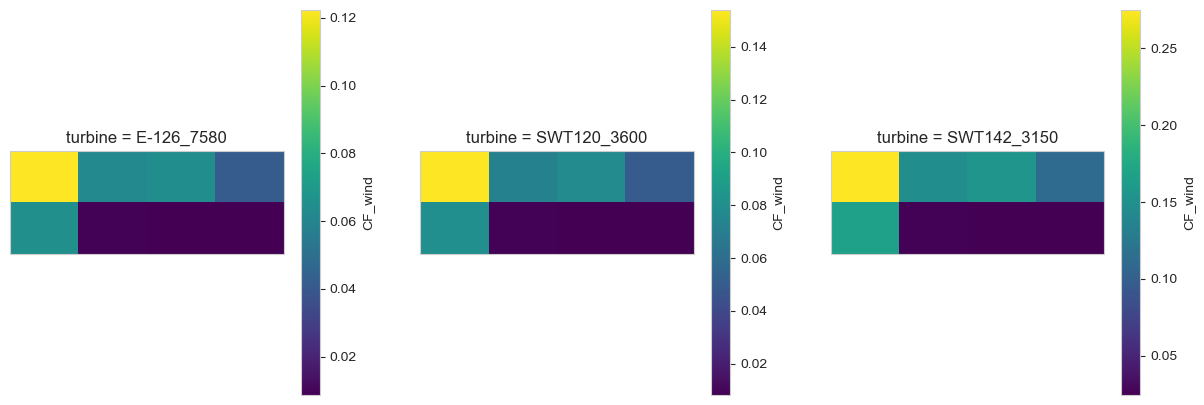

In [ ]:
fig, axes = plt.subplots(
    1, 3, figsize=(15, 5), subplot_kw={"projection": ccrs.PlateCarree()}
)
axes = axes.flatten()
for i, turbine_cesm in enumerate(ds_cesm.turbine.values):
    sel_extent(ds_cesm, extent=extent_ch).sel(turbine=turbine_cesm).mean(
        dim="time"
    ).CF_wind.plot(ax=axes[i])